## Module 3: Computational Drug Discovery Project

Matt Cherry, Faye Chiang, and Mieraf Bisrat

## Project Goal:

You are working as a Quantitative Systems Pharmacologist at the UVA Manning Institute for Biotechnology. Your overall goal is to help develop a GLP1 agonist drug for weight loss, branded Cavalitide, that will compete with semaglutide (Ozempic or Wegovy). Your project is composed of three tasks:
* Task 1: Fit a receptor binding (pharmacodynamics) model for Cavalitide
* Task 2: Simulate the pharmacokinetics of Cavalitide treatment
* Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment.
  
The below sections should be addressed in your Project Report as a Jupyter notebook, based on Module3_Project_Template.ipynb. All groups submit a Project Report, only those in the Sullivan Company have Oral Presentations (**all due 11/17**).

## Disease Background: 

Obesity is a chronic disease influenced by genetic, hormonal, environmental, and behavioral factors that affect appetite, metabolism, and fat storage (Saucerman, 2026c). In 2022, about one in eight people worldwide lived with obesity, showing how substantial obesity is (World Health Organization [WHO], 2024). In adults, obesity is classified as a body mass index (BMI) of at least 30 kg/m² and increases the risk of type 2 diabetes, cardiovascular disease, and several cancers (WHO, 2026). As discussed in Module 3 Lecture 1 (Saucerman, 2026c), altered signaling between the gut, brain, pancreas, and adipose tissue can disrupt fullness and glucose regulation. GLP-1 receptor agonists, such as semaglutide, target these pathways to support appetite control and weight loss (Saucerman, 2026c). Treatment includes nutrition and physical activity changes, medications, and metabolic surgery (WHO, 2026). 

## Task 1: Fit a receptor binding model for Cavalitide:

Your colleague in Lead Discovery has identified a small molecule, Cavalitide, and performed experiments testing its binding to the GLP1 receptor (below, and available as cavalitide_data.csv). You now aim to develop a pharmacodynamics model of how GLP1 and Cavalitide can each bind and activate the GLP1 receptor.

a)	Adapt your previous codes for modeling semaglutide (fit_semaglutide.py, semaglutide_data.csv) to fit the Cavalitide binding data.

b)	Show a plot of [Cavalitide] vs. Fraction active receptors (Fact) demonstrating a good fit.

c)	Provide the fitted value of Kd for Cavalitide. Interpret the Kd of Cavalitide versus that of semaglutide, commenting on advantages/disadvantages.

### Task 1a: Model and fitting method
We adapted the instructor's `fit_semaglutide_GLP1R.py` example, keeping its brute-force search and `curve_fit` approach (Saucerman, 2026b). The only additional analysis is an approximate 95% confidence interval for Cavalitide Kd.

The model assumes GLP1 and Cavalitide compete for one receptor binding site at equilibrium, and that either ligand fully activates the receptor. GLP1 is fixed at the example's fasting concentration, 0.015 nM, with Kd = 0.17 nM. Free ligand concentrations are approximated by the supplied concentrations. Only Cavalitide Kd is fitted. All 12 observations receive equal weight (Saucerman, 2026a). The 0.38 nM semaglutide value is the instructor's reference (Saucerman, 2026d, slides 12–15).

### Task 1b: Fit and plot


Brute-force Kd2 = 0.074 nM (SSE = 0.0054)
Fitted Kd2 = 0.077 nM (SSE = 0.0052)
Kd standard error = 0.00454 nM
Approximate 95% confidence interval = [0.06806, 0.08587] nM


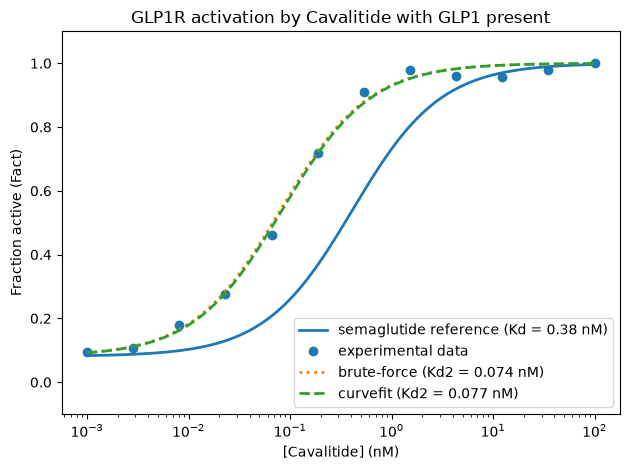

In [ ]:
%matplotlib inline
# fit_cavalitide_GLP1R.py
# Adapted from the instructor's fit_semaglutide_GLP1R.py example.

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def Fact(L1, L2, Kd1, Kd2):
    """Fractional receptor activation with two agonists L1 and L2"""
    return (Kd2*L1+Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

# Parameters [nM]
Kd1 = 0.17 # L1, GLP1
Kd2 = 0.38 # semaglutide reference
L1 = 0.015 # [nM] GLP1 (fasting)
L2 = np.logspace(-3, 2, 500) # [nM] semaglutide or cavalitide

# Load the data
data = np.loadtxt("cavalitide_data.csv", delimiter=",", skiprows=1)
L2_loaded, Fact_loaded = data[:, 0], data[:, 1]

# Approach 1: Brute force optimization of Kd2. try many candidate values in a for loop
Kd2_candidates = np.logspace(-3, 2, 100) # [nM]
SSE_brute = np.inf
for Kd2_try in Kd2_candidates:
    # Sum of squared errors between the data and the model for this candidate
    SSE = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_try))**2)
    if SSE < SSE_brute:
        SSE_brute = SSE
        Kd2_brute = Kd2_try
print(f"Brute-force Kd2 = {Kd2_brute:.3f} nM (SSE = {SSE_brute:.4f})")

# Approach 2: Python curvefit of Kd2. related to steepest descent method
popt, pcov = curve_fit(lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2),
                       L2_loaded, Fact_loaded, p0=[0.1], bounds=(0, np.inf))
Kd2_fit = popt[0]
SSE_fit = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_fit))**2)
print(f"Fitted Kd2 = {Kd2_fit:.3f} nM (SSE = {SSE_fit:.4f})")


# Extra analysis: approximate 95% confidence interval for Cavalitide Kd.
# The square root of the fitted variance gives the standard error.
Kd2_se = np.sqrt(pcov[0, 0])
ci_low = Kd2_fit - 1.96 * Kd2_se
ci_high = Kd2_fit + 1.96 * Kd2_se
print(f"Kd standard error = {Kd2_se:.5f} nM")
print(f"Approximate 95% confidence interval = [{ci_low:.5f}, {ci_high:.5f}] nM")

plt.figure()
line, = plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2), lw=2,
                     label="semaglutide reference (Kd = 0.38 nM)")
plt.semilogx(L2_loaded, Fact_loaded, "o", c=line.get_color(),
             label="experimental data")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_brute), ":", lw=2,
             label=f"brute-force (Kd2 = {Kd2_brute:.3f} nM)")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_fit), "--", lw=2,
             label=f"curvefit (Kd2 = {Kd2_fit:.3f} nM)")

plt.ylim(-0.1, 1.1)
plt.xlabel("[Cavalitide] (nM)")
plt.ylabel("Fraction active (Fact)")
plt.title("GLP1R activation by Cavalitide with GLP1 present")
plt.legend(loc="best")
plt.tight_layout()
plt.savefig("cavalitide_fit.png", dpi=200)
plt.show()


### Task 1c: Results and interpretation
The fitted Cavalitide Kd is approximately 0.077 nM, compared with the instructor's semaglutide reference of 0.38 nM (Saucerman, 2026d). Cavalitide's Kd is about 4.9 times lower, indicating higher affinity. It can therefore reach the same modeled receptor activation at a lower free drug concentration when GLP1 is fixed. The fitted curve follows the observed increase toward full activation. The brute-force estimate is approximately 0.074 nM (SSE = 0.0054), close to the continuous fit (SSE = 0.0052). 

Higher affinity could be an advantage if lower free concentrations can provide the desired activation. A possible tradeoff is that a concentration chosen for semaglutide could produce more activation than intended for Cavalitide, so dosing would need to be adjusted. This fit also does not establish side effects, weight loss, length of action, or oral absorption. Those would require other models or experiments. Both drugs approach the same maximum activation in the assumed model.

### Extra analysis: Approximate 95% confidence interval
We calculated the standard error as `sqrt(pcov[0, 0])` and the approximate interval as Kd ± 1.96 × standard error, using the fitted covariance to estimate the standard error (SciPy community, n.d.-b). The standard error is approximately 0.00454 nM, giving an interval of 0.06806–0.08587 nM. This estimates uncertainty in the fitted Cavalitide Kd.

With only 12 points, the interval is approximate and does not include uncertainty from model assumptions. It is not a formal two-drug statistical comparison because uncertainty in semaglutide Kd was not included.

*Model and data sources: Saucerman (2026a, 2026b, 2026d). Covariance interpretation: SciPy community (n.d.-b).*

*AI assistance for Task 1: ChatGPT assisted in writing the approximate confidence-interval calculation and helped write the interpretation.*


## Task 2: Simulate the pharmacokinetics of Cavalitide treatment

Your boss is really excited about the progress of your team in Task 1 on the development of Cavalitide. You’re now assigned to help design the Phase 1 clinical trial for the pill version of Cavalitide.

a) Review the example code for modeling semaglutide pharmacokinetics
(semaglutidePK.py). Run simulations for both Ozempic (subcutaneous injection
once per week) and Wegovy (daily pill). Replace the portion of the code using an
explicit Euler’s method with use of the more powerful built-in function
scipy.integrate.solve_ivp. Rerun the code to create plots that compare the predicted
profiles of Ozempic and Wegovy.

b) Now, adapt semaglutidePK.py to additionally incorporate simulations of Cavalitide
(daily pill), which has an increased absorption rate ka = 0.006 1/h. Plot how
Cavalitide blood concentration changes over time.

c) Given the higher absorption rate, you hypothesize that you can further optimize the
dosing strategy. Adjust one or two drug or dosing specific parameters until you
achieve a steady state free blood concentration close to 0.5 nM. Plot your result.
What did you change about the dosing strategy and why?

### Task 2a: Replace Euler's Method with "solve_ivp"

We replaced the explicit Euler's method in the provided code with scipy.integrate.solve_ivp (Saucerman, 2026e; SciPy community, n.d.-c). The model tracks drug remaining at the absorption site and total drug concentration in blood. At each dose, Favailable × D is added to the absorption site. Between doses, drug is absorbed into blood and eliminated.

We retained the instructor's parameters and dosing regimens for Ozempic and Wegovy. Blood concentration was converted from mg/L to nM and multiplied by the free fraction, 0.01, to obtain free blood concentration.

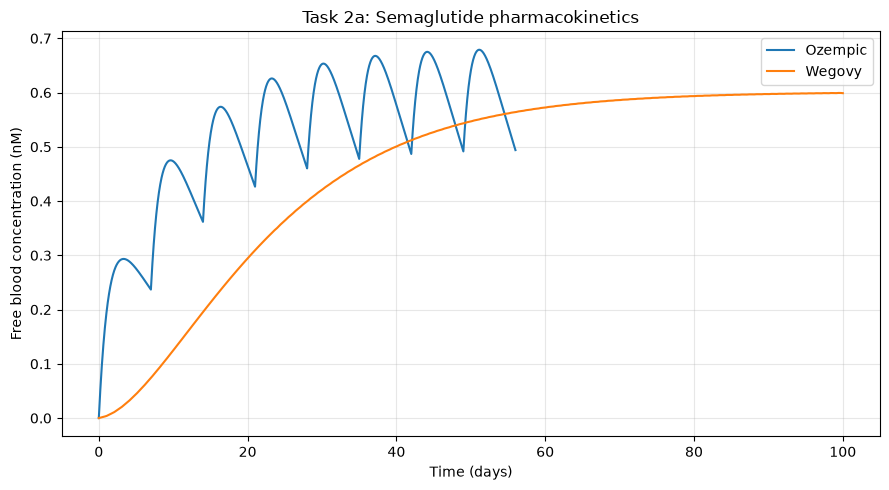

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Shared model parameters from the instructor's code
ke = 0.0039     # elimination rate, 1/h
V = 10.8        # blood distribution volume, L
MW = 4113.6     # molecular weight, g/mol
Ffree = 0.01    # fraction of blood drug that is free

products = {
    "Ozempic": {
        "Favailable": 0.89,
        "ka": 0.029,
        "D": 2.0,
        "interval": 168,
        "n_doses": 8
    },
    "Wegovy": {
        "Favailable": 0.01,
        "ka": 0.0029,
        "D": 25,
        "interval": 24,
        "n_doses": 100
    }
}

def ODEfunc(t, y, ka):
    Asc, Cc = y

    dAsc = -ka * Asc
    dCc = ka * Asc / V - ke * Cc

    return [dAsc, dCc]

def simulate(p):
    t_out = []
    Asc_out = []
    Cc_out = []

    # Initially, no drug at the absorption site or in blood
    y = np.array([0.0, 0.0])

    for i in range(p["n_doses"]):
        # Add the next dose to the absorption site
        y[0] += p["Favailable"] * p["D"]

        t0 = i * p["interval"]
        t1 = t0 + p["interval"]

        # Times at which we want the results reported
        t_eval = np.linspace(t0, t1, 241)

        sol = solve_ivp(
            ODEfunc,
            (t0, t1),
            y,
            args=(p["ka"],),
            t_eval=t_eval,
            rtol=1e-8,
            atol=1e-10
        )

        if not sol.success:
            raise RuntimeError(sol.message)

        t_out.append(sol.t)
        Asc_out.append(sol.y[0])
        Cc_out.append(sol.y[1])

        # Preserve the remaining drug for the next dosing interval
        y = sol.y[:, -1].copy()

    t = np.concatenate(t_out)
    Asc = np.concatenate(Asc_out)
    Cc = np.concatenate(Cc_out)

    # Convert total blood concentration from mg/L to nM
    Cc_nM = Cc * 1e6 / MW

    # Only the free fraction is used for the target concentration
    Cfree_nM = Ffree * Cc_nM

    return t, Asc, Cfree_nM

plt.figure(figsize=(9, 5))

for name, p in products.items():
    t, Asc, Cfree = simulate(p)
    plt.plot(t / 24, Cfree, label=name)

plt.xlabel("Time (days)")
plt.ylabel("Free blood concentration (nM)")
plt.title("Task 2a: Semaglutide pharmacokinetics")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Ozempic produces noticeable weekly peaks and troughs, while the modeled daily Wegovy regimen produces a smoother concentration profile. Both regimens show drug accumulation with repeated dosing. The original settings simulate Ozempic for 56 days and Wegovy for 100 days, so the curves end at different times.

### Task 2b: Add Cavalitide with Faster Absorption

We added Cavalitide using the oral dosing parameters and increased the absorption rate constant from 0.0029 to 0.006 1/h. Because no other Cavalitide parameters were provided, we assumed its bioavailability, elimination rate, distribution volume, molecular weight, and free fraction were unchanged from the oral example. The dose remained 25 mg every 24 hours for 100 doses.

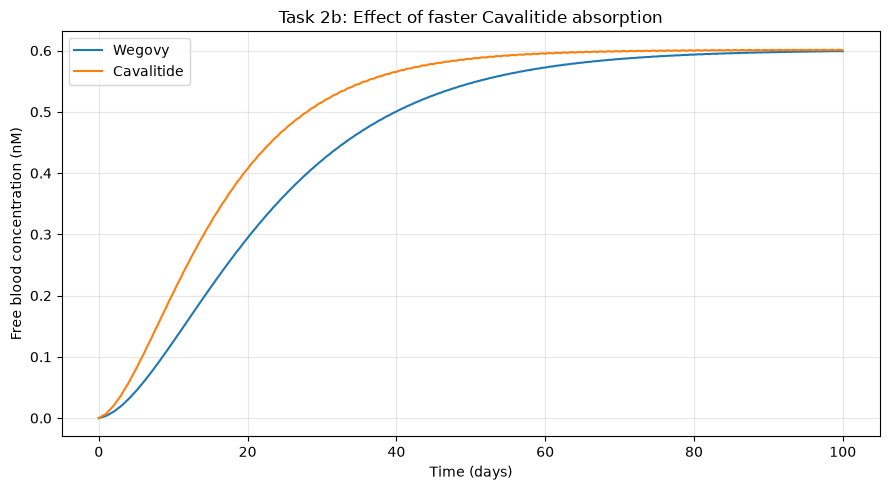

In [3]:
# Assume all other Cavalitide parameters equal the oral example
products["Cavalitide"] = products["Wegovy"].copy()
products["Cavalitide"]["ka"] = 0.006

plt.figure(figsize=(9, 5))

for name in ["Wegovy", "Cavalitide"]:
    t, Asc, Cfree = simulate(products[name])
    plt.plot(t / 24, Cfree, label=name)

plt.xlabel("Time (days)")
plt.ylabel("Free blood concentration (nM)")
plt.title("Task 2b: Effect of faster Cavalitide absorption")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Cavalitide approaches its long-term concentration pattern faster because of its higher absorption rate. However, faster absorption does not increase bioavailability. With the same bioavailability, dose, and elimination rate, the two oral regimens have the same average steady-state concentration, approximately 0.601 nM.

### Task 2c: Adjust the Code to Approach 0.5 nM

We reduced the Cavalitide dose while keeping daily administration and the absorption rate constant of 0.006 1/h. In this linear model, average steady-state concentration is proportional to dose.

The average steady-state free concentration is:

Cfree_ss = Ffree × Favailable × D × 10^6 / (ke × V × interval × MW)

Solving for a target concentration of 0.5 nM gives a dose of approximately 20.79 mg every 24 hours.

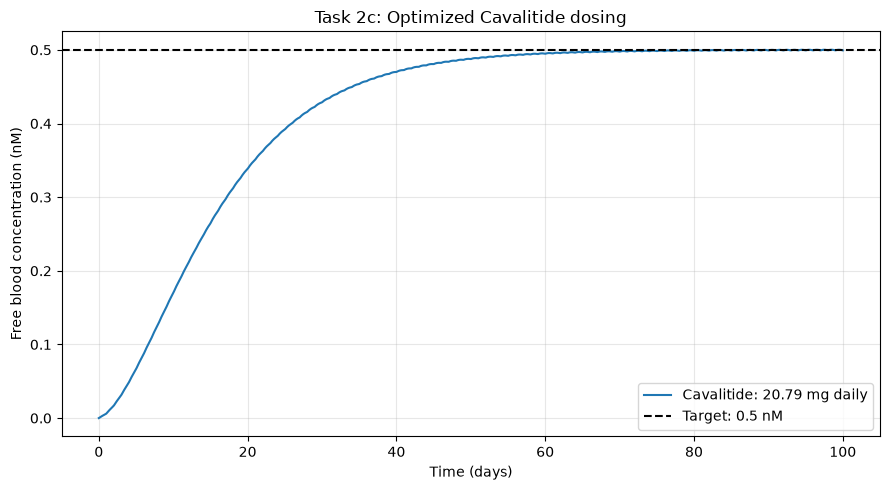

Optimized dose: 20.79 mg every 24 hours
Final-day minimum: 0.4993 nM
Final-day maximum: 0.5002 nM


In [4]:
target = 0.5  # target free blood concentration, nM

# Copy the Cavalitide regimen
optimized = products["Cavalitide"].copy()

# Calculate the dose needed for an average of 0.5 nM
optimized["D"] = (
    target * ke * V * optimized["interval"] * MW
    / (Ffree * optimized["Favailable"] * 1e6)
)

# Simulate the optimized regimen
t, Asc, Cfree = simulate(optimized)

plt.figure(figsize=(9, 5))
plt.plot(
    t / 24,
    Cfree,
    label=f"Cavalitide: {optimized['D']:.2f} mg daily"
)
plt.axhline(
    target,
    color="black",
    linestyle="--",
    label="Target: 0.5 nM"
)

plt.xlabel("Time (days)")
plt.ylabel("Free blood concentration (nM)")
plt.title("Task 2c: Optimized Cavalitide dosing")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Check the final daily dosing interval
last_interval = Cfree[-241:]

print(f"Optimized dose: {optimized['D']:.2f} mg every 24 hours")
print(f"Final-day minimum: {last_interval.min():.4f} nM")
print(f"Final-day maximum: {last_interval.max():.4f} nM")

Reducing the dose from 25 mg to approximately 20.79 mg daily brought the modeled free blood concentration close to the 0.5 nM target. During the final dosing interval, concentration ranged from approximately 0.4993 to 0.5002 nM.

We changed only the dose because the original daily regimen produced a concentration above the target. Daily administration maintained small concentration fluctuations. Steady state under repeated dosing is a repeating concentration pattern rather than a perfectly constant concentration.

These predictions depend on the assumed pharmacokinetic parameters and do not establish clinical safety or effectiveness.

### Additional analysis: Sensitivity to daily dose

We simulated Cavalitide doses of 15, 20.79, 25, and 30 mg daily,
holding all other parameters constant. We compared the full
100-day concentration profiles and examined the final five days
to show the daily peaks and troughs near steady state.

This analysis evaluates how dose selection affects achievement
of the 0.5 nM target.

Dose sensitivity analysis
--------------------------------------------------------------
 Dose (mg)    Minimum (nM)    Maximum (nM)    Average (nM)
     15.00          0.3602          0.3608          0.3606
     20.79          0.4993          0.5002          0.4999
     25.00          0.6004          0.6014          0.6011
     30.00          0.7204          0.7217          0.7213


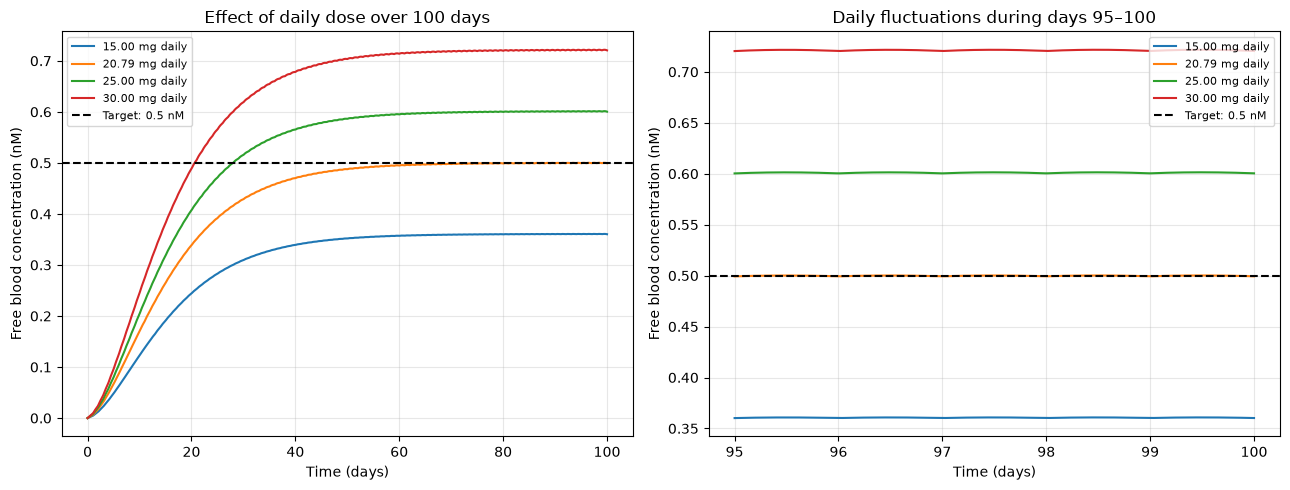

In [5]:
# Compare several doses while keeping other parameters unchanged
doses = [15, optimized["D"], 25, 30]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

print("Dose sensitivity analysis")
print("-" * 62)
print(
    f"{'Dose (mg)':>10} {'Minimum (nM)':>15} "
    f"{'Maximum (nM)':>15} {'Average (nM)':>15}"
)

for dose in doses:
    # Create a separate regimen for each dose
    p = optimized.copy()
    p["D"] = dose

    t, Asc, Cfree = simulate(p)
    days = t / 24

    # Full treatment profile
    line, = axes[0].plot(
        days, Cfree, label=f"{dose:.2f} mg daily"
    )

    # Zoom in on the final five days
    mask = days >= 95
    axes[1].plot(
        days[mask],
        Cfree[mask],
        color=line.get_color(),
        label=f"{dose:.2f} mg daily"
    )

    # Calculate statistics over the final dosing interval
    last_t = t[-241:]
    last_C = Cfree[-241:]

    # Time-weighted average using trapezoidal integration
    average = np.sum(
        0.5 * (last_C[1:] + last_C[:-1]) * np.diff(last_t)
    ) / (last_t[-1] - last_t[0])

    print(
        f"{dose:10.2f} {last_C.min():15.4f} "
        f"{last_C.max():15.4f} {average:15.4f}"
    )

for ax in axes:
    ax.axhline(
        0.5,
        color="black",
        linestyle="--",
        label="Target: 0.5 nM"
    )
    ax.set_xlabel("Time (days)")
    ax.set_ylabel("Free blood concentration (nM)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_title("Effect of daily dose over 100 days")
axes[1].set_title("Daily fluctuations during days 95–100")

plt.tight_layout()
plt.show()

The average concentration near steady state increased proportionally with daily dose, consistent with the model's linear absorption and elimination equations. The approximate final-day average concentrations were 0.361, 0.500, 0.601, and 0.721 nM for daily doses of 15, 20.79, 25, and 30 mg, respectively.

The optimized dose stayed closest to the 0.5 nM target. The zoomed graph also revealed small daily peaks and troughs, demonstrating that repeated dosing produces a periodic steady state.

These results describe sensitivity to dose under fixed model parameters. They do not account for differences in absorption elimination, or other parameters between patients.

## Task 3: Simulate a combined pharmacokinetics-pharmacokinetics (PKPD) model that predicts GLP1 receptor activity during treatment
The Phase 1 clinical trial was a success, and you achieved the desired 0.5 nM
concentration of Cavalitide in your patients. Now it’s time to further customize the dosing
for the Phase 2 clinical trial, where you’re more interested in efficacy. You’ll need to
combine the PK model (Task 2) and PD model (Task 1) to predict how the fraction of
activated receptors changes over time.

a) Embed the ligand-receptor model of Cavalitide (from Task 1, but just using your
optimized Kd) into your cavalitidePK.py model. Let’s call this combined model
cavalitidePKPD.py. Predict how the fraction of active GLP1R receptors changes over
the first 100 days of treatment.

b) Further optimize your dosing strategy so that you achieve close to 90% active GLP1
receptors at steady state (around 100 days). Which dosing parameters did you
adjust? Provide an interpretation of the clinical benefits of this adjustment.

## Task 3a: Build the PKPD Model

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

# Pharmacokinetic (PK) parameters
ke = 0.0039
ka = 0.006
V = 10.8
MW = 4113.6

Ffree = 0.01
Favailable = 0.01

D = 20.79
interval = 24
n_doses = 100

# Pharmacodynamic (PD) parameters
Kd_GLP1 = 0.17
Kd_Cavalitide = 0.077
GLP1 = 0.015

# PHARMACOKINETIC MODEL

def ODEfunc(t, y):

    Asc, Cc = y

    dAsc = -ka * Asc
    dCc = (ka * Asc / V) - (ke * Cc)

    return [dAsc, dCc]


def simulate_PK(dose):

    # Initial conditions
    y = [0, 0]

    time_values = []
    concentration_values = []

    # Simulate 100 daily doses
    for i in range(n_doses):

        # Add daily dose to absorption compartment
        y[0] += Favailable * dose

        t_start = i * interval
        t_end = (i + 1) * interval

        t_eval = np.linspace(t_start, t_end, 241)

        # Solve differential equations
        solution = solve_ivp(
            ODEfunc,
            [t_start, t_end],
            y,
            t_eval=t_eval
        )

        # Store results
        if i == 0:
            time_values.extend(solution.t)
            concentration_values.extend(solution.y[1])
        else:
            time_values.extend(solution.t[1:])
            concentration_values.extend(solution.y[1][1:])

        # Carry final values into next dosing interval
        y = [
            solution.y[0][-1],
            solution.y[1][-1]
        ]

    # Convert concentration from mg/L to nM
    Cc = np.array(concentration_values)
    Cc_nM = Cc * 1e6 / MW

    # Calculate free Cavalitide concentration
    Cfree = Ffree * Cc_nM

    return np.array(time_values), Cfree

# PHARMACODYNAMIC MODEL

def Fact(GLP1, Cavalitide, Kd1, Kd2):

    numerator = (Kd2 * GLP1) + (Kd1 * Cavalitide)

    denominator = (
        (Kd1 * Kd2)
        + (Kd2 * GLP1)
        + (Kd1 * Cavalitide)
    )

    return numerator / denominator

# COMBINE PK AND PD MODELS

def simulate_PKPD(dose):

    t, Cfree = simulate_PK(dose)

    activation = Fact(
        GLP1,
        Cfree,
        Kd_GLP1,
        Kd_Cavalitide
    )

    return t, Cfree, activation

# TASK 3A: SIMULATE RECEPTOR ACTIVATION USING ORIGINAL DOSE

# Use original daily dose of 20.79 mg
t, Cfree, activation = simulate_PKPD(D)

# Examine the final 24 hours
final_activation = activation[-241:] * 100

# Print Task 3A results
print("\nTASK 3A RESULTS")
print("---------------------------------------")
print(f"Original dose: {D:.2f} mg/day")
print(f"Minimum activation: {final_activation.min():.2f}%")
print(f"Maximum activation: {final_activation.max():.2f}%")
print(f"Average activation: {final_activation.mean():.2f}%")


# Plot Task 3A
plt.figure(figsize=(10, 5))

plt.plot(
    t / 24,
    activation * 100,
    linewidth=2,
    label="Original Cavalitide Dose"
)

plt.xlabel("Time (days)")
plt.ylabel("Fraction of Active GLP1 Receptors (%)")
plt.title("Task 3A: Cavalitide GLP1 Receptor Activation")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig("cavalitide_PKPD.png", dpi=200)
plt.show()


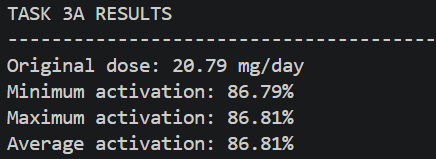

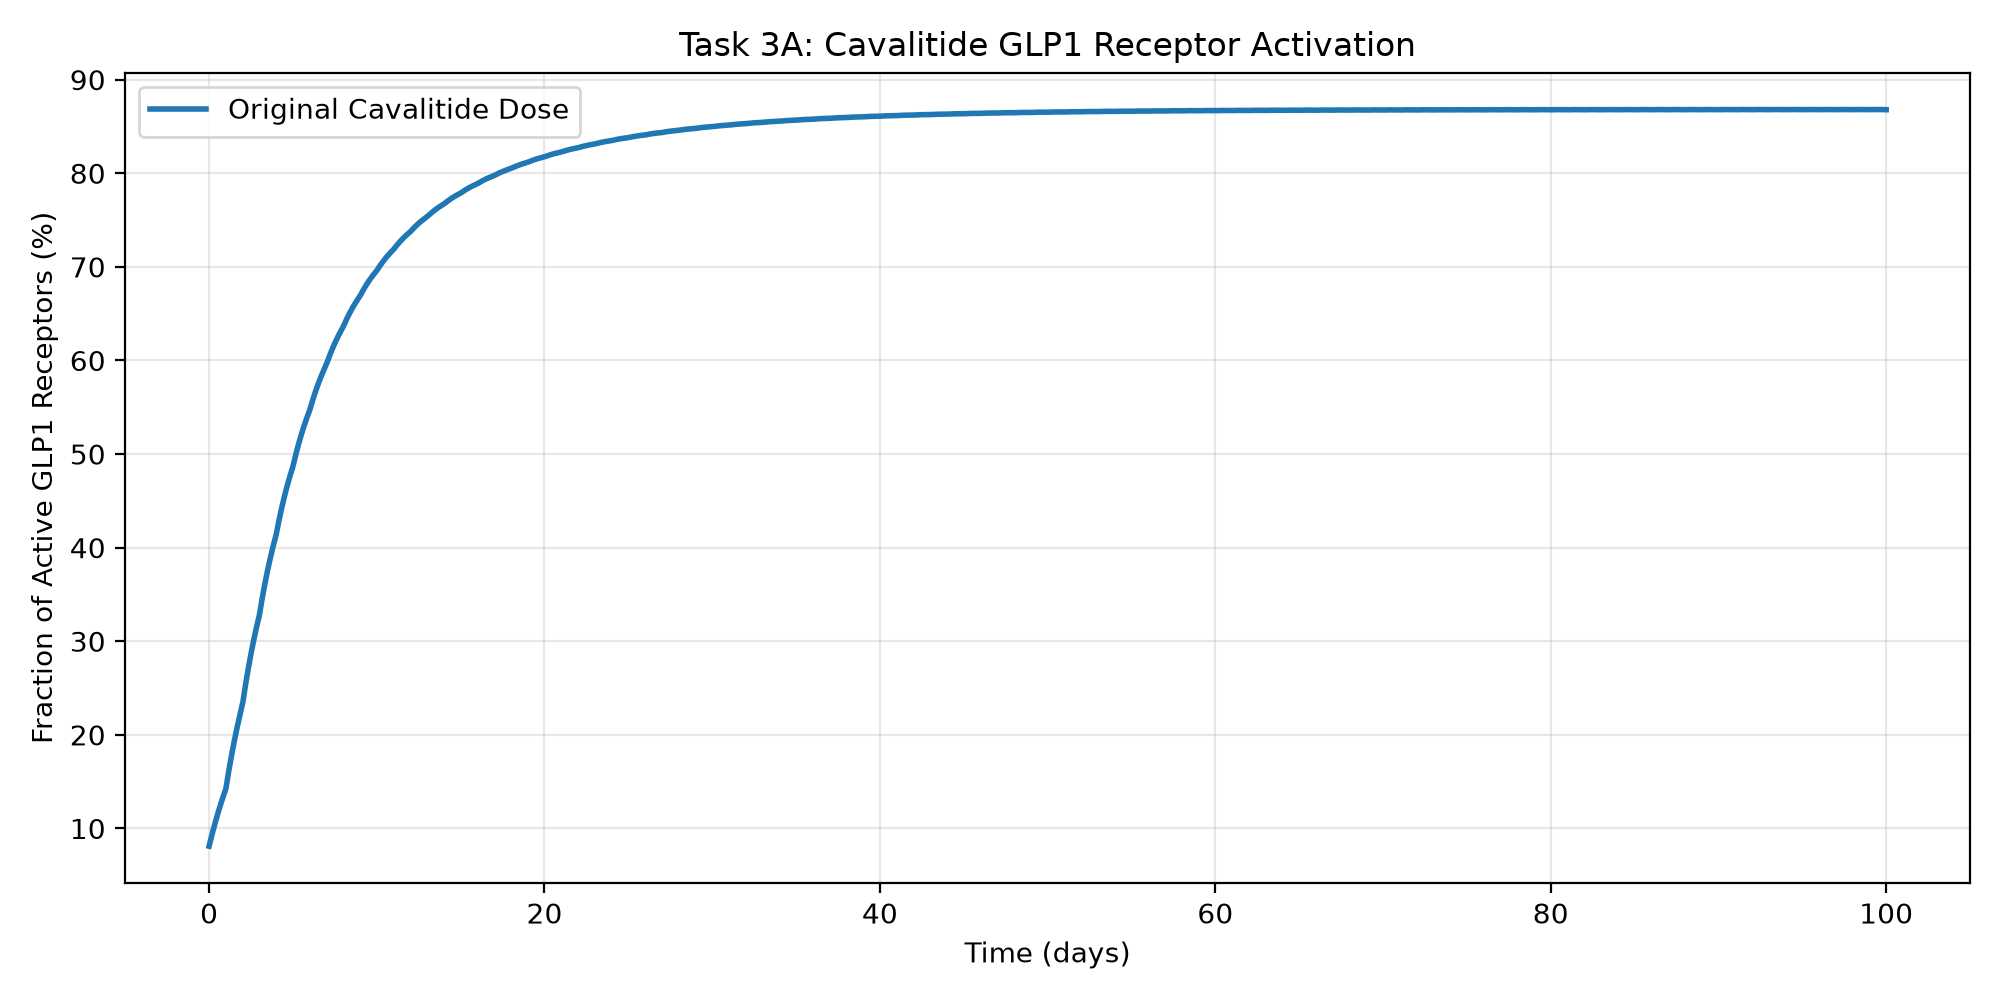

We combined our PK model from Task 2 with our PD model from Task 1 to predict GLP1 receptor activation over 100 days. We used our optimized Cavalitide (K_d) of 0.077 nM and the original daily dose of 20.79 mg. As shown in the graph, receptor activation gradually increases as the drug accumulates with repeated dosing before reaching a relatively stable level. During the final 24 hours, the model predicted an average receptor activation of 86.81%.

## Task 3b: Optimize the Cavalitide dose to achieve approximately 90% GLP1 receptor activation.

In [ ]:
# TASK 3B: OPTIMIZE THE DAILY CAVALITIDE DOSE

# Calculate average receptor activation for a given dose
def activation_at_dose(dose):

    t_test, Cfree_test, activation_test = simulate_PKPD(dose)

    # Select final 24 hours
    final_interval = activation_test[-241:]
    final_time = t_test[-241:]

    # Calculate time-weighted average activation
    average_activation = (
        np.trapezoid(final_interval, final_time)
        / (final_time[-1] - final_time[0])
    ) * 100

    return average_activation


# Find dose that produces 90% average receptor activation
optimized_dose = brentq(
    lambda dose: activation_at_dose(dose) - 90,
    20,
    50
)


# Print Task 3B optimization results
print("\nTASK 3B RESULTS")
print("---------------------------------------")
print(f"Original dose: {D:.2f} mg/day")
print(f"Optimized dose: {optimized_dose:.2f} mg/day")
print(
    f"Average receptor activation: "
    f"{activation_at_dose(optimized_dose):.2f}%"
)
# SIMULATE PKPD MODEL USING OPTIMIZED DOSE

t_opt, Cfree_opt, activation_opt = simulate_PKPD(optimized_dose)

# Examine final 24 hours
final_activation_opt = activation_opt[-241:] * 100


# Print optimized final-day results
print("\nOPTIMIZED FINAL 24-HOUR RESULTS")
print("---------------------------------------")
print(f"Minimum activation: {final_activation_opt.min():.2f}%")
print(f"Maximum activation: {final_activation_opt.max():.2f}%")
print(f"Average activation: {final_activation_opt.mean():.2f}%")

# PLOT TASK 3B: OPTIMIZED RECEPTOR ACTIVATION


plt.figure(figsize=(10, 5))

plt.plot(
    t_opt / 24,
    activation_opt * 100,
    linewidth=2,
    label="Optimized Cavalitide Dose"
)

plt.axhline(
    90,
    linestyle="--",
    label="90% Activation Target"
)

plt.xlabel("Time (days)")
plt.ylabel("Fraction of Active GLP1 Receptors (%)")
plt.title("Task 3B: Optimized Cavalitide GLP1 Receptor Activation")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig("cavalitide_PKPD_optimized.png", dpi=200)
plt.show()

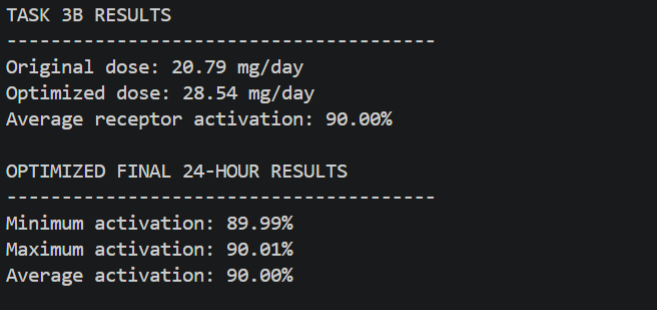

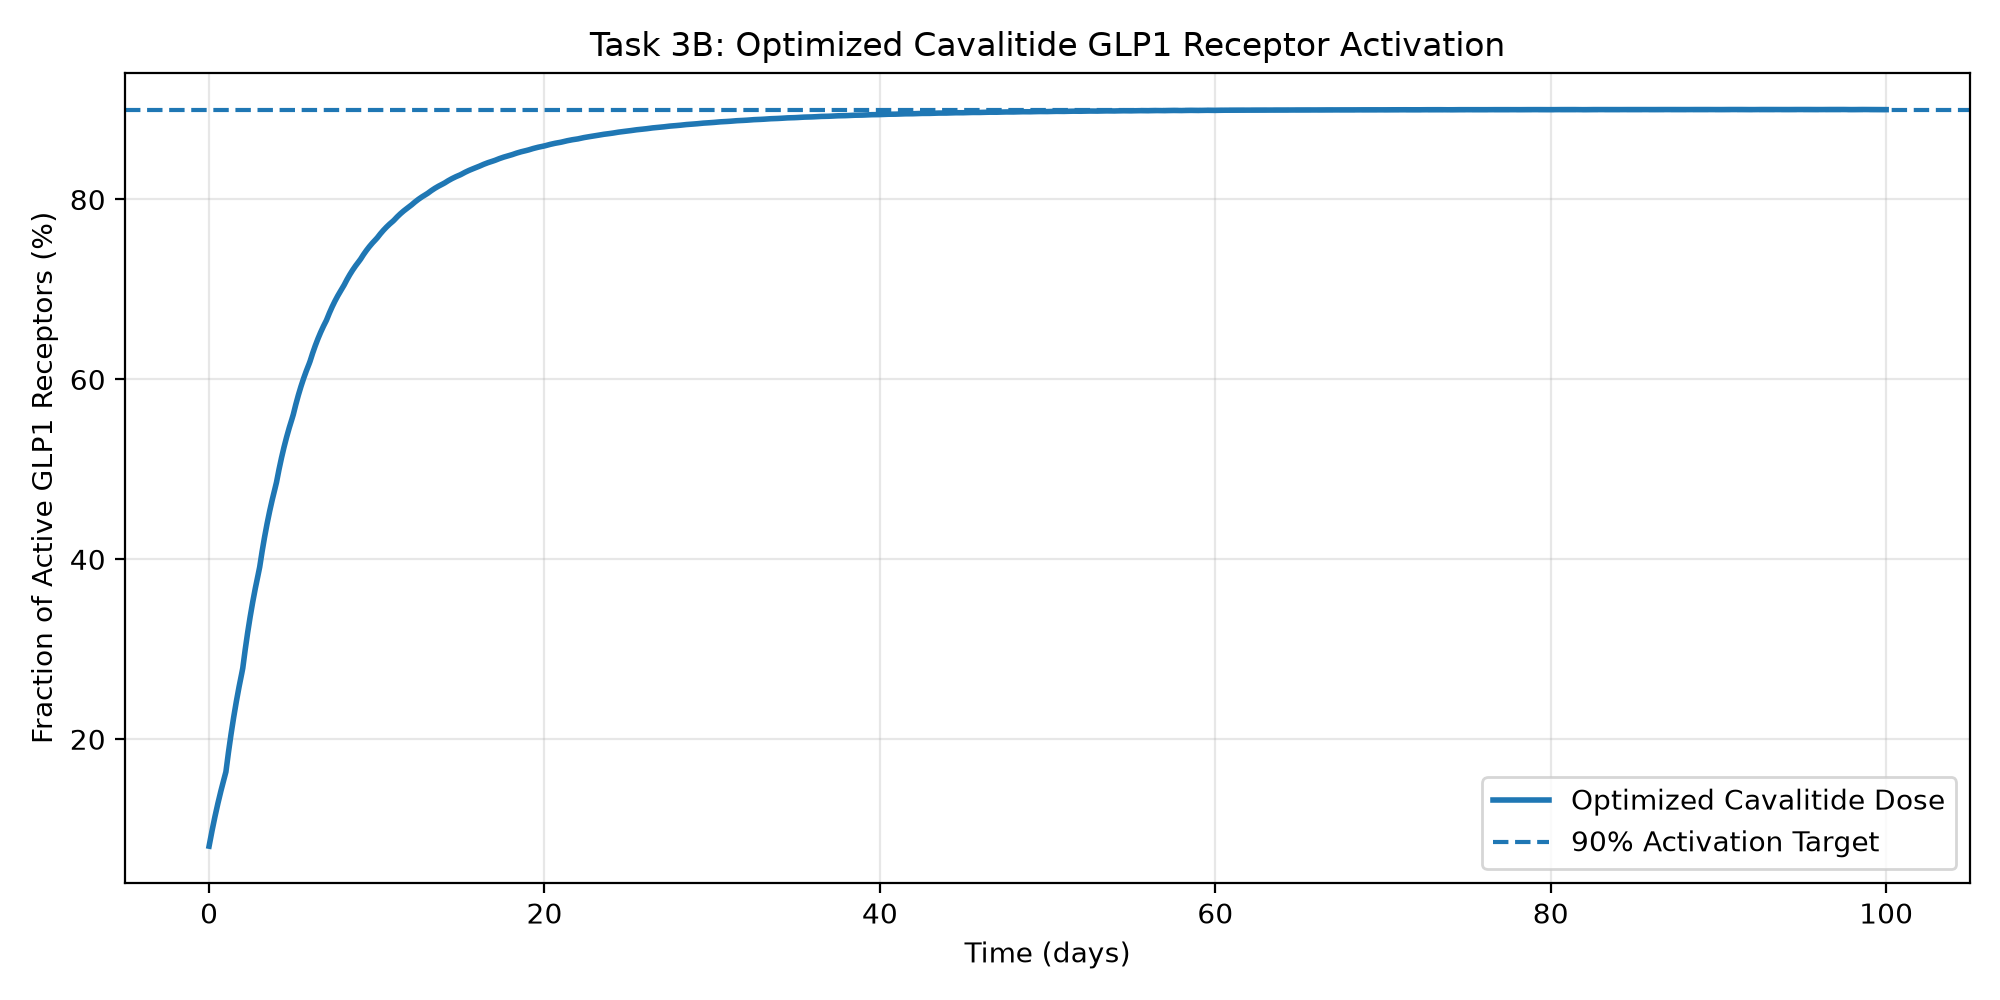

We adjusted the daily Cavalitide dose to achieve approximately 90% GLP1 receptor activation at steady state. We kept the other pharmacokinetic parameters constant, including the absorption rate, elimination rate, bioavailability, and 24-hour dosing interval. We used numerical optimization to determine the daily dose that would produce the desired receptor activation using `brentq` (SciPy community, n.d.-a).

The original dose of 20.79 mg/day resulted in approximately 86.81% average receptor activation. After optimization, the model identified a daily dose of 28.54 mg/day, which produced approximately 90.00% average activation during the final 24 hours of treatment.

Increasing the dose could potentially improve Cavalitide's therapeutic effect by increasing the fraction of activated GLP1 receptors. However, higher receptor activation does not necessarily guarantee better clinical outcomes, and increasing the dose could also increase the risk of adverse effects. Therefore, the optimized dose would need to be evaluated for both safety and efficacy during clinical trials.

## Extra Analyses

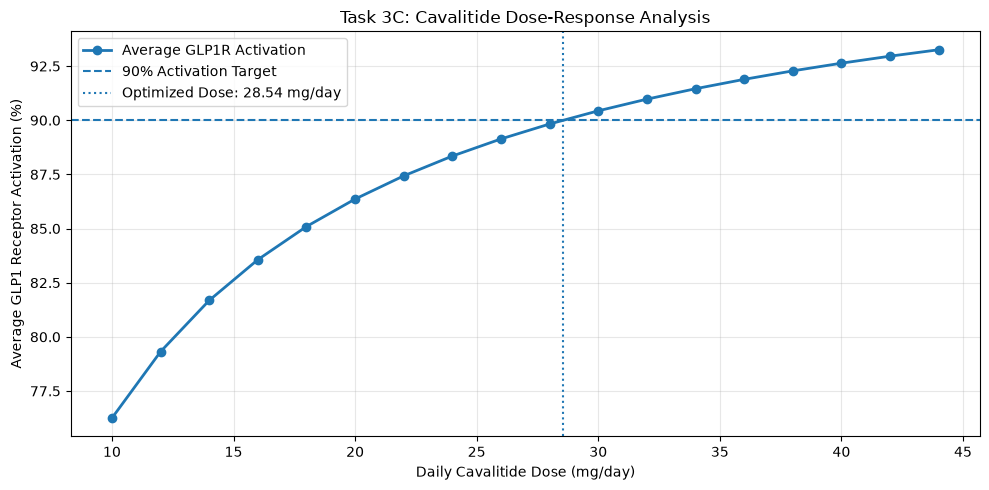


TASK 3C: SENSITIVITY ANALYSIS
---------------------------------------
Baseline optimized dose: 28.54 mg/day
Absorption rate (ka) (-20%): Optimized dose = 28.55 mg/day | Change = +0.02%
Absorption rate (ka) (+20%): Optimized dose = 28.54 mg/day | Change = -0.01%
Elimination rate (ke) (-20%): Optimized dose = 22.85 mg/day | Change = -19.93%
Elimination rate (ke) (+20%): Optimized dose = 34.24 mg/day | Change = +19.98%
Binding affinity (Kd) (-20%): Optimized dose = 22.83 mg/day | Change = -20.00%
Binding affinity (Kd) (+20%): Optimized dose = 34.25 mg/day | Change = +20.00%


In [8]:
# TASK 3C: Additional Analyses - Dose-Response and Sensitivity Analysis

# PART 1: DOSE-RESPONSE ANALYSIS

# Test different daily Cavalitide doses
dose_range = np.arange(10, 46, 2)

activation_range = []

for dose in dose_range:

    average_activation = activation_at_dose(dose)

    activation_range.append(average_activation)


# Plot dose-response relationship
plt.figure(figsize=(10, 5))

plt.plot(
    dose_range,
    activation_range,
    marker="o",
    linewidth=2,
    label="Average GLP1R Activation"
)

plt.axhline(
    90,
    linestyle="--",
    label="90% Activation Target"
)

plt.axvline(
    optimized_dose,
    linestyle=":",
    label=f"Optimized Dose: {optimized_dose:.2f} mg/day"
)

plt.xlabel("Daily Cavalitide Dose (mg/day)")
plt.ylabel("Average GLP1 Receptor Activation (%)")

plt.title("Task 3C: Cavalitide Dose-Response Analysis")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig("cavalitide_dose_response.png", dpi=200)
plt.show()

# PART 2: SENSITIVITY ANALYSIS

# Investigate how changes in model parameters
# affect the optimized Cavalitide dose.


# Save original parameter values
original_ka = ka
original_ke = ke
original_Kd = Kd_Cavalitide


# Store baseline optimized dose
baseline_dose = optimized_dose


# Define parameters to investigate
parameters = {
    "Absorption rate (ka)": "ka",
    "Elimination rate (ke)": "ke",
    "Binding affinity (Kd)": "Kd_Cavalitide"
}


# Store results
sensitivity_results = []


# Change each parameter by -20% and +20%
for parameter_name, parameter_variable in parameters.items():

    original_value = globals()[parameter_variable]

    for change in [-0.20, 0.20]:

        # Reset parameters so only one changes at a time
        ka = original_ka
        ke = original_ke
        Kd_Cavalitide = original_Kd

        # Apply parameter change
        globals()[parameter_variable] = original_value * (1 + change)

        # Find new dose required for 90% activation
        new_dose = brentq(
            lambda dose: activation_at_dose(dose) - 90,
            5,
            80
        )

        # Calculate percentage difference from baseline dose
        dose_difference = (
            (new_dose - baseline_dose) / baseline_dose
        ) * 100

        sensitivity_results.append(
            (parameter_name, change * 100, new_dose, dose_difference)
        )


# Restore original parameters
ka = original_ka
ke = original_ke
Kd_Cavalitide = original_Kd


print("\nTASK 3C: SENSITIVITY ANALYSIS")
print("---------------------------------------")

print(f"Baseline optimized dose: {baseline_dose:.2f} mg/day")

for parameter, change, new_dose, difference in sensitivity_results:

    print(
        f"{parameter} ({change:+.0f}%): "
        f"Optimized dose = {new_dose:.2f} mg/day | "
        f"Change = {difference:+.2f}%"
    )

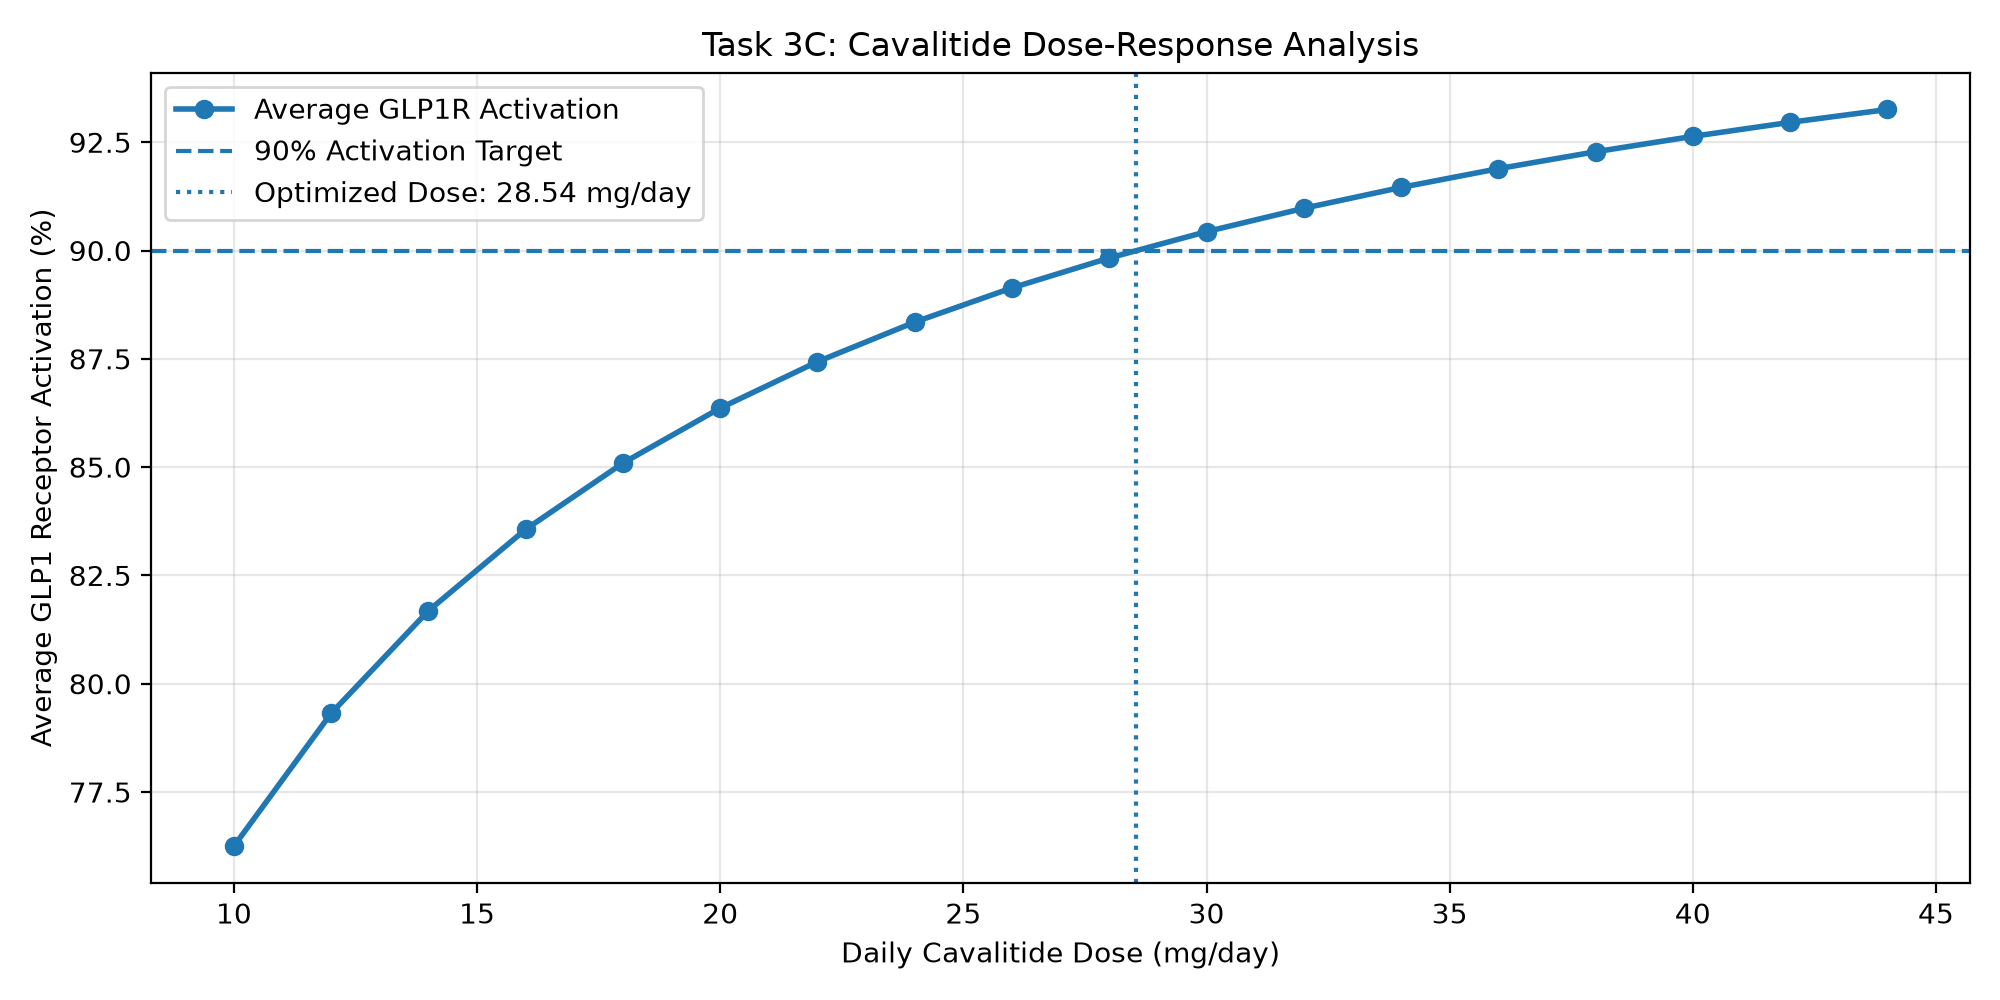

We performed a dose-response analysis and sensitivity analysis to see how changes in different parameters affected the model. We tested the effects of changing the absorption rate ((k_a)), elimination rate ((k_e)), and binding affinity ((K_d)) by ±20%, changing one parameter at a time.

The results showed that changing the absorption rate had almost no effect on the optimized dose. However, changing the elimination rate and binding affinity had a much larger effect. For example, increasing the elimination rate by 20% increased the required dose to 34.24 mg/day. Increasing the (K_d) by 20%, meaning weaker binding affinity, increased the required dose to 34.25 mg/day. The elimination rate and binding affinity had similar effects, with a 20% increase in either parameter increasing the required dose by about 20%. This showed that the predicted dose is more sensitive to elimination rate and binding affinity than absorption rate.

## Verification and Validation

We checked our numerical results against calculations from the model equations. The brute-force estimate of Cavalitide Kd was 0.074 nM, close to the curve_fit estimate of 0.077 nM. The smaller SSE from curve_fit was expected because the brute-force search only tested a fixed set of values. Using the steady-state concentration equation from Task 2, a daily dose of 20.79 mg gives an average free concentration of approximately 0.5000 nM, consistent with the simulated final-day average of 0.4999 nM. Solving the receptor model for 90% activation and converting the required concentration to a daily dose gives approximately 28.53 mg/day, close to the numerical result of 28.54 mg/day. This last check uses the average steady-state concentration, while the numerical optimization averages activation over the final day. Their close agreement is consistent with the small daily fluctuations in our simulation. These checks support the calculations, but do not show that the assumptions match real patients.

For comparison with published experiments, Granhall et al. (2019) reported a semaglutide half-life of approximately one week in trials of oral semaglutide. Our elimination rate of 0.0039 1/h gives a half-life of ln(2) / 0.0039 = 177.7 hours, or 7.41 days. This is approximately 6% longer than seven days and is consistent with the study's approximate value. The study also found approximately twice the exposure with 40 mg compared with 20 mg oral semaglutide in healthy male participants. Our linear PK model predicts a twofold increase in exposure when dose doubles, which agrees with that reported trend (Granhall et al., 2019).

This comparison supports the general scale of semaglutide elimination and the model's dose-proportional behavior. However, the elimination rate was provided in the course example and may already reflect published semaglutide data, so the half-life agreement is a consistency check rather than fully independent validation. The study used oral semaglutide with an absorption enhancer, different doses, and specific participant groups. We did not fit or compare complete concentration-time curves from the study. These results do not validate Cavalitide's assumed PK parameters or show that 90% receptor activation will produce a particular amount of weight loss. Measured Cavalitide concentrations, receptor responses, and clinical outcomes would be needed for that validation.


## Conclusions:

From our analyses, we have concluded Cavalitide has the potential to compete with semaglutide as an oral GLP-1 receptor agonist. As shown in Task 1, Cavalitide’s Kd of approximately 0.077 nM was about five times lower than semaglutide’s reference value of 0.38 nM (Saucerman, 2026d), indicating stronger receptor binding and activation at the same drug concentration. In Task 2, our pharmacokinetic simulations identified a daily dose of approximately 20.79 mg that maintained a steady-state concentration near 0.5 nM. Combining the binding and pharmacokinetic models in Task 3 predicted that increasing the dose to approximately 28.54 mg/day would achieve 90% average receptor activation. These findings support investigation of Cavalitide as an oral treatment option for obesity.

The corrected sensitivity analysis also showed that elimination rate and Kd had similar effects on the dose needed for 90% activation. Increasing either parameter by 20% increased the required dose by about 20%, while changing absorption rate had little effect near steady state. This suggests that measuring Cavalitide's elimination rate and binding affinity accurately would be important before selecting a dose.

Our recommendation is to investigate the predicted dose further rather than use it as a clinical dosing recommendation. Granhall et al. (2019) reported gastrointestinal disorders as the most common adverse events in their oral semaglutide trials. Our model does not predict these effects, so higher receptor activation alone cannot show whether increasing a dose is worthwhile for patients. Ethical decisions should balance potential benefits with adverse effects and consider whether treatment is affordable and accessible. Because we did not model cost, insurance coverage, or patient differences, we cannot claim that Cavalitide would be safer, more affordable, or equally effective for everyone. These factors should be evaluated alongside clinical outcomes before recommending Cavalitide over semaglutide.


## Limitations and Future Work:

A limitation of this model is that some of the pharmacokinetic parameters used for Cavalitide were assumed rather than experimentally measured. The actual drug concentration in the body could be different from what the model predicts because the absorption rate and bioavailability were based on assumptions. The model also does not account for individual differences between patients because it assumes that the drug follows the same pharmacokinetic behavior throughout the entire 100 day treatment.
 
A second limitation is that the receptor activation does not represent actual clinical effectiveness. Even though the model predicts 90% GLP1 receptor activation at a daily does of 28.54 mg, it does not guarantee improved patient outcomes or establish the safety of the dose.

Future work could incorporate clinical trial data to refine the accuracy of the pharmacokinetic (PK) and pharmacodynamic (PD) parameters. Additionally, the model could be expanded to account for patient-to-patient variability, potential adverse effects, and fluctuations in drug absorption and elimination. Finally, evaluating a broader range of dosing regimens could help identify an optimal dose that balances receptor activation, safety, and efficacy.

## AI Usage Statement:

We used OpenAI's ChatGPT in Task 1 to help write the code for the approximate 95% confidence interval and interpret the fitted binding affinity. In Task 2, ChatGPT helped replace Euler’s method with solve_ivp and adapt the pharmacokinetic simulations. In Task 3, ChatGPT helped combine the PK and PD models, implement dose optimization and additional analyses, explain coding concepts, and troubleshoot errors. We also used ChatGPT to improve the organization of our project, gather our thoughts, create APA citations, and edit the wording of our explanations.

## GitHub Repository Link:
https://github.com/BigPanda0226/BME2315_Module3


## References

Granhall, C., Donsmark, M., Blicher, T. M., Golor, G., Søndergaard, F. L., Thomsen, M., & Bækdal, T. A. (2019). Safety and pharmacokinetics of single and multiple ascending doses of the novel oral human GLP-1 analogue, oral semaglutide, in healthy subjects and subjects with type 2 diabetes. *Clinical Pharmacokinetics, 58*(6), 781–791. https://doi.org/10.1007/s40262-018-0728-4

Saucerman, J. (2026a). *cavalitide_data.csv* [Data set]. BME 2315, University of Virginia. Canvas. https://canvas.its.virginia.edu/courses/189803/files/folder/Module%203%20-%20Saucerman

Saucerman, J. (2026b). *fit_semaglutide_GLP1R.py* [Python code]. BME 2315, University of Virginia. Canvas. https://canvas.its.virginia.edu/courses/189803/files/folder/Module%203%20-%20Saucerman

Saucerman, J. (2026c). *Module 3 lecture 1: Computational drug discovery* [PowerPoint slides]. BME 2315, University of Virginia. Canvas. https://canvas.its.virginia.edu/courses/189803/files/folder/Module%203%20-%20Saucerman

Saucerman, J. (2026d). *Module 3 lecture 2* [PowerPoint slides]. BME 2315, University of Virginia. Canvas. https://canvas.its.virginia.edu/courses/189803/files/folder/Module%203%20-%20Saucerman

Saucerman, J. (2026e). *semaglutidePK.py* [Python code]. BME 2315, University of Virginia. Canvas. https://canvas.its.virginia.edu/courses/189803/files/folder/Module%203%20-%20Saucerman

SciPy community. (n.d.-a). *brentq*. SciPy documentation. https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.brentq.html

SciPy community. (n.d.-b). *curve_fit*. SciPy documentation. https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.curve_fit.html

SciPy community. (n.d.-c). *solve_ivp*. SciPy documentation. https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html

World Health Organization. (2024, March 1). *One in eight people are now living with obesity*. https://www.who.int/news/item/01-03-2024-one-in-eight-people-are-now-living-with-obesity

World Health Organization. (2026, October 7). *Obesity and overweight*. https://www.who.int/news-room/fact-sheets/detail/obesity-and-overweight


## NOTES FROM YOUR TEAM: 
None.

## QUESTIONS FOR YOUR TA: 
None.